# CDS4003 – Data Science Final Project
## Notebook 03 – Stages 5 and 6: Model Selection, Hyperparameter Tuning and Evaluation

**Prerequisite:** notebooks 01 and 02 completed (cleaned data, `src/vehicle_features.py`).
**Outputs:** model comparison, tuning and evaluation tables/figures in `outputs/`, and the final model `models/price_model.joblib` with `models/model_metadata.json`.

### Setup
The next cells load the libraries, connect to your Drive project folder, import the shared feature code and read only the columns needed for modelling.

In [ ]:
# ---- Libraries ----
import re
import sys
import json
import shutil
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.simplefilter("ignore", category=FutureWarning)      # hides harmless deprecation notices only
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

IN_COLAB = "google.colab" in sys.modules

# ---- Project folder in Google Drive (shared by notebooks 01-04) ----
if IN_COLAB:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/Used-Vehicle-Price-Prediction")
else:
    PROJECT_DIR = Path("Used-Vehicle-Price-Prediction")

RAW_DIR, PROCESSED_DIR, SAMPLE_DIR = PROJECT_DIR / "data/raw", PROJECT_DIR / "data/processed", PROJECT_DIR / "data/sample"
OUTPUT_DIR, FIG_DIR = PROJECT_DIR / "outputs", PROJECT_DIR / "outputs/figures"
NOTEBOOK_DIR, MODEL_DIR, APP_DIR, SRC_DIR, DOCS_DIR = (PROJECT_DIR / n for n in ["notebooks", "models", "app", "src", "docs"])

settings_path = OUTPUT_DIR / "cleaning_settings.json"
if not settings_path.exists():
    raise FileNotFoundError(f"{settings_path} not found. Run notebook 01 completely first (it saves the cleaned data and settings "
                            f"in {PROJECT_DIR}).")
for folder in [FIG_DIR, MODEL_DIR, APP_DIR, SRC_DIR, DOCS_DIR, NOTEBOOK_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# ---- Settings decided in notebook 01 (the same rules are used everywhere) ----
cleaning_settings = json.loads(settings_path.read_text(encoding="utf-8"))
DATA_COLLECTION_YEAR = cleaning_settings["DATA_COLLECTION_YEAR"]
PRICE_MAX_PLAUSIBLE = cleaning_settings["PRICE_MAX_PLAUSIBLE"]
PRICE_LOW_REVIEW = cleaning_settings["PRICE_LOW_REVIEW"]

def std_name(name):
    """Standard column name: stripped, lowercase, spaces replaced by underscores."""
    return re.sub(r"\s+", "_", str(name).strip().lower())

def load_cleaned(usecols=None):
    """Read the cleaned dataset saved by notebook 01."""
    path = PROCESSED_DIR / "vehicles_cleaned.csv"
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Run notebook 01 completely first.")
    df = pd.read_csv(path, usecols=usecols, low_memory=False, keep_default_na=False, na_values=[""])
    if "posting_date" in df.columns:
        df["posting_date"] = pd.to_datetime(df["posting_date"], errors="coerce", utc=True)
    return df

def save_fig(name):
    """Save the current figure into outputs/figures (used as report evidence)."""
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    return path

print(f"Project folder          : {PROJECT_DIR}")
print(f"Data-collection year    : {DATA_COLLECTION_YEAR}")
print(f"Records after cleaning  : {cleaning_settings['records_cleaned']:,} (from {cleaning_settings['records_raw']:,} raw records)")

Mounted at /content/drive
Project folder          : /content/drive/MyDrive/Used-Vehicle-Price-Prediction
Data-collection year    : 2026
Records after cleaning  : 240,186 (from 295,451 raw records)


In [ ]:
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
try:
    import vehicle_features as vf
except ImportError as error:
    raise ImportError("src/vehicle_features.py not found. Run notebook 02 completely first.") from error

# Only the model inputs and the target are loaded (saves memory)
wanted_columns = set(vf.RAW_INPUT_COLUMNS + ["price"])            # columns absent in your dataset version are treated as "unknown"
df_cleaned = load_cleaned(usecols=lambda column: column in wanted_columns)
print(f"Modelling table loaded: {df_cleaned.shape}")
display(df_cleaned.head(3))

Modelling table loaded: (240186, 15)


,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state,seller_type
0,27999,2022.0,ford,explorer st,excellent,6 cylinders,gas,99179.0,clean,automatic,4wd,suv,grey,ca,dealer
1,2200,1969.0,volkswagen,bug,fair,4 cylinders,gas,90000.0,clean,manual,rwd,other,green,ca,owner
2,15999,2016.0,rover,sport,excellent,6 cylinders,gas,82896.0,clean,automatic,4wd,suv,white,ca,dealer


---
# STAGE 5 – Model Selection and Development

**Goal:** compare several suitable regression models fairly, justify the final candidates, and show whether the engineered features add value.

**Design choices**
- **Target:** `log(price)` is predicted and converted back to dollars. This weights errors by *percentage* and handles the skewed price distribution (Section 18).
- **Leakage prevention:** the imputer, scaler and encoders live **inside** a scikit-learn `Pipeline`, so they are fitted on training data only. The test set is touched only for final reporting; models are chosen with **cross-validation on the training data**.
- **Baseline:** a model that always predicts the median price shows what "no learning" achieves.

## 22. Modelling Setup, Features and Train/Test Split

**What will happen?** The modelling table is built, split into training and test sets, and the settings are defined.

### Settings (edit if you have more time or memory)
| Setting | Default | Meaning |
|---|---|---|
| `MODEL_SAMPLE_SIZE` | 120,000 | Rows used for modelling so that the notebook finishes on a free Colab runtime. Use `None` for all rows. |
| `RF_TREES` | 80 | Number of trees of the random forest. |
| `CV_SAMPLE` / `CV_FOLDS` | 30,000 / 3 | Size of the subsample and number of folds for cross-validation. |

### Which columns are used – and which are not
| Used as model inputs | Excluded and why |
|---|---|
| `year`, `odometer`, `manufacturer`, `model`, `condition`, `cylinders`, `fuel`, `title_status`, `transmission`, `drive`, `size`, `type`, `paint_color`, `seller_type` (if present), `state` plus the engineered features | `id`, `url`, `region_url`, `image_url`, `VIN` – identifiers, not vehicle attributes |
| | `flag_*` columns – the price flags are **derived from the target** (leakage) |
| | `description`, `posting_date`, `lat`, `long`, `region` – not provided by a user of the app or need extra processing |

**Known limitation:** confirmed re-posts were removed in Stage 3, but *similar* listings (same vehicle attributes, different text) were kept and can still fall in both training and test sets, which can make test scores slightly optimistic.

In [ ]:
import time
from scipy.stats import randint, loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import make_scorer, mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_predict, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler
import sklearn

# ----------------------------- MODELLING SETTINGS -----------------------------
MODEL_SAMPLE_SIZE = 120_000
TEST_SIZE = 0.2
RANDOM_STATE = 42
CV_FOLDS = 3
CV_SAMPLE = 30_000
RF_TREES = 80
MIN_CAT_FREQ = 50          # categories with fewer listings are grouped together inside the encoders
# -------------------------------------------------------------------------------

df_model = df_cleaned.reindex(columns=vf.RAW_INPUT_COLUMNS + ["price"]).copy()
if MODEL_SAMPLE_SIZE and len(df_model) > MODEL_SAMPLE_SIZE:
    df_model = df_model.sample(n=MODEL_SAMPLE_SIZE, random_state=RANDOM_STATE)

X = df_model[vf.RAW_INPUT_COLUMNS]
y = df_model["price"].astype(float)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)

print(f"scikit-learn version: {sklearn.__version__}")
print(f"Rows used for modelling: {len(df_model):,}  (training {len(X_train):,} | test {len(X_test):,})")
print(f"Input columns ({X.shape[1]}): {list(X.columns)}")
print(f"Training price: median ${y_train.median():,.0f} | test price: median ${y_test.median():,.0f}")

scikit-learn version: 1.6.1
Rows used for modelling: 120,000  (training 96,000 | test 24,000)
Input columns (15): ['year', 'odometer', 'manufacturer', 'model', 'condition', 'cylinders', 'fuel', 'title_status', 'transmission', 'drive', 'size', 'type', 'paint_color', 'seller_type', 'state']
Training price: median $12,999 | test price: median $12,999


In [ ]:
def rmsle_score(y_true, y_pred):
    """Root mean squared error on the log scale (a percentage-style error)."""
    return float(np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(np.clip(y_pred, 0, None)))))

rmsle_scorer = make_scorer(rmsle_score, greater_is_better=False)

def regression_metrics(y_true, y_pred):
    """Technical and business metrics, all calculated on the dollar scale unless stated."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.clip(np.asarray(y_pred, dtype=float), 1, None)
    ape = np.abs(y_pred - y_true) / y_true
    return {"RMSE ($)": float(np.sqrt(mean_squared_error(y_true, y_pred))), "MAE ($)": float(mean_absolute_error(y_true, y_pred)),
            "R2": float(r2_score(y_true, y_pred)), "RMSLE": rmsle_score(y_true, y_pred),
            "MAPE (%)": float(ape.mean() * 100), "MdAPE (%)": float(np.median(ape) * 100),
            "Within 10% (%)": float((ape <= 0.10).mean() * 100), "Within 20% (%)": float((ape <= 0.20).mean() * 100)}

def make_pipeline(kind, engineered=True):
    """Full pipeline: feature engineering -> preprocessing -> model (predicting log price, returning dollars)."""
    if engineered:
        num_cols, cat_cols = vf.NUMERIC_FEATURES, vf.CATEGORICAL_FEATURES
    else:                                           # baseline feature set for the 'do engineered features help?' experiment
        num_cols, cat_cols = ["year", "odometer"], vf.CATEGORICAL_RAW

    ordinal = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1, min_frequency=MIN_CAT_FREQ)
    if kind in ("dummy", "ridge"):
        numeric = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())])
        categorical = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=MIN_CAT_FREQ)
    elif kind == "rf":
        numeric = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True))])
        categorical = ordinal
    elif kind == "hgb":
        numeric, categorical = "passthrough", ordinal          # HistGradientBoosting handles missing numbers natively
    else:
        raise ValueError(f"Unknown model kind: {kind}")

    estimators = {
        "dummy": DummyRegressor(strategy="median"),
        "ridge": Ridge(alpha=1.0),
        "rf": RandomForestRegressor(n_estimators=RF_TREES, min_samples_leaf=2, max_features=0.5, n_jobs=-1, random_state=RANDOM_STATE),
        "hgb": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, early_stopping=True, random_state=RANDOM_STATE),
    }
    preprocess = ColumnTransformer([("num", numeric, num_cols), ("cat", categorical, cat_cols)], remainder="drop")
    model = TransformedTargetRegressor(regressor=estimators[kind], func=np.log1p, inverse_func=vf.inverse_log_price, check_inverse=False)
    return Pipeline([("features", FunctionTransformer(vf.add_features, validate=False)), ("prep", preprocess), ("model", model)])

cv_splitter = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
X_cv = X_train.sample(n=min(CV_SAMPLE, len(X_train)), random_state=RANDOM_STATE)
y_cv = y_train.loc[X_cv.index]

def cv_scores(pipeline, X_data, y_data):
    """Cross-validated RMSLE and R2 (training data only)."""
    scores = cross_validate(pipeline, X_data, y_data, cv=cv_splitter, scoring={"rmsle": rmsle_scorer, "r2": "r2"}, n_jobs=1)
    return {"cv_rmsle": -scores["test_rmsle"].mean(), "cv_rmsle_std": scores["test_rmsle"].std(), "cv_r2": scores["test_r2"].mean()}

print("Helper functions defined. Quick pipeline test on 2,000 rows:")
_check = make_pipeline("hgb").fit(X_train.head(2000), y_train.head(2000))
print("  prediction sample ($):", np.round(_check.predict(X_test.head(3)), 0))

Helper functions defined. Quick pipeline test on 2,000 rows:
  prediction sample ($): [ 5778. 21787.  6956.]


## 23. The Candidate Models and Why They Fit the Problem

| Model | How it works (plain language) | Why it fits this problem | Weakness |
|---|---|---|---|
| **Baseline (median)** | Always predicts the median training price. | Shows the performance of "no learning"; every real model must beat it. | Ignores all attributes. |
| **Ridge regression** | Fits one straight-line formula: price (in log form) = sum of weights × features. A penalty keeps the weights small and stable. | Simple, fast and **interpretable**; a good benchmark for how much non-linear models add. | Cannot capture curved relationships or interactions (for example mileage matters differently for old and new cars). |
| **Random forest** | Builds many decision trees on random parts of the data and averages their predictions. | Captures non-linear effects and interactions; robust to outliers; few settings to tune. | Slower, large model file, can over-fit noisy listings. |
| **Histogram gradient boosting** | Builds trees one after another; each new tree corrects the errors of the previous ones. | Often the most accurate on tabular data; fast; handles missing values natively; small model file. | More settings to tune; can over-fit if not regularised. |

Models are compared on the **same split**, with **cross-validation** (3-fold on the training data) for fair selection, and on the **test set** for final reporting.

## 24. Training and Comparing the Models

**What will happen?** Each model is trained on the training set and evaluated with cross-validation (training data) and on the untouched test set. A simple experiment also checks whether the engineered features improve the best model.

**Expected output:** a comparison table, charts, and the feature-engineering experiment. Random forest is the slowest model (a few minutes with the default settings).

In [ ]:
MODEL_LABELS = {"dummy": "Baseline (median)", "ridge": "Ridge regression", "rf": "Random forest", "hgb": "Hist. gradient boosting"}
default_models, comparison_rows = {}, []

for kind, label in MODEL_LABELS.items():
    pipeline = make_pipeline(kind)
    start = time.time()
    pipeline.fit(X_train, y_train)
    fit_seconds = time.time() - start
    default_models[kind] = pipeline

    train_part = X_train.head(min(20_000, len(X_train)))
    train_metrics = regression_metrics(y_train.loc[train_part.index], pipeline.predict(train_part))
    test_metrics = regression_metrics(y_test, pipeline.predict(X_test))
    cv = cv_scores(make_pipeline(kind), X_cv, y_cv)
    comparison_rows.append({"Model": label, "key": kind, "CV RMSLE": cv["cv_rmsle"], "CV RMSLE std": cv["cv_rmsle_std"],
                            "CV R2": cv["cv_r2"], "Train R2": train_metrics["R2"], "Test R2": test_metrics["R2"],
                            "Test RMSE ($)": test_metrics["RMSE ($)"], "Test MAE ($)": test_metrics["MAE ($)"],
                            "Test MdAPE (%)": test_metrics["MdAPE (%)"], "Test Within 20% (%)": test_metrics["Within 20% (%)"],
                            "Fit time (s)": fit_seconds})
    print(f"{label:<26} trained in {fit_seconds:6.1f}s | CV RMSLE {cv['cv_rmsle']:.3f} | test R2 {test_metrics['R2']:.3f}")

model_comparison = pd.DataFrame(comparison_rows).set_index("Model")
display(model_comparison.drop(columns="key").round(3))
model_comparison.drop(columns="key").to_csv(OUTPUT_DIR / "model_comparison.csv")

Baseline (median)          trained in    1.5s | CV RMSLE 1.053 | test R2 -0.066
Ridge regression           trained in    3.1s | CV RMSLE 0.793 | test R2 0.395
Random forest              trained in   25.2s | CV RMSLE 0.703 | test R2 0.704
Hist. gradient boosting    trained in    6.5s | CV RMSLE 0.692 | test R2 0.676


,CV RMSLE,CV RMSLE std,CV R2,Train R2,Test R2,Test RMSE ($),Test MAE ($),Test MdAPE (%),Test Within 20% (%),Fit time (s)
Model,,,,,,,,,,
Baseline (median),1.053,0.021,-0.073,-0.080,-0.066,21770.158,11400.315,53.350,18.088,1.529
Ridge regression,0.793,0.026,0.307,0.460,0.395,16405.647,6819.944,27.992,37.171,3.091
Random forest,0.703,0.028,0.577,0.906,0.704,11473.084,4126.114,16.851,55.679,25.198
Hist. gradient boosting,0.692,0.027,0.594,0.805,0.676,12005.898,4712.833,19.066,51.842,6.461


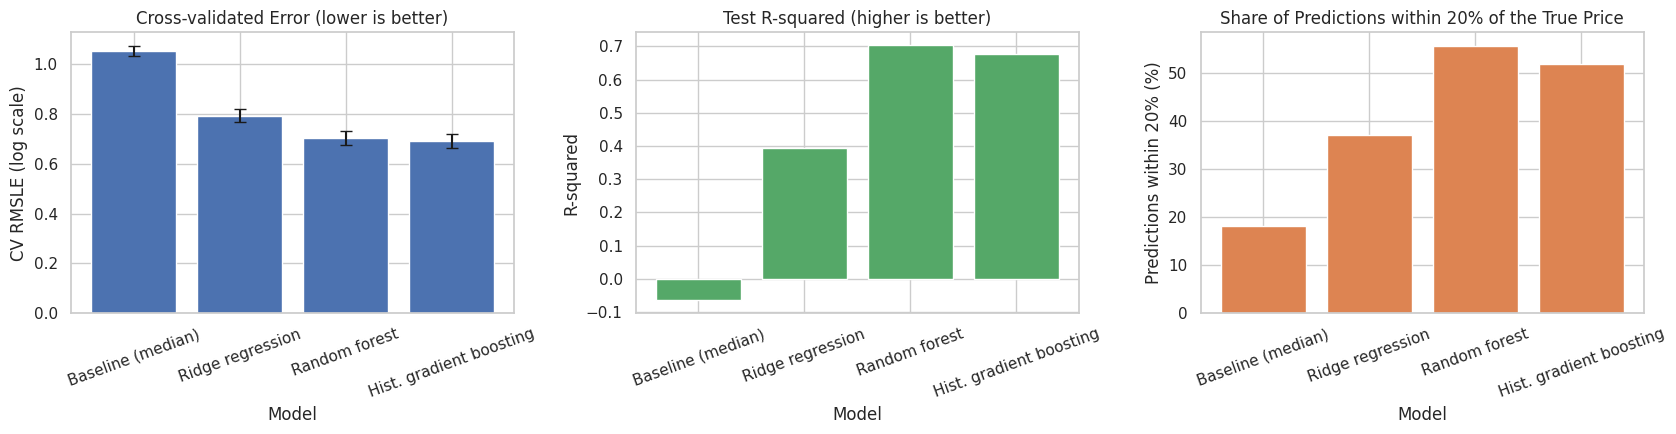

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
plot_df = model_comparison.reset_index()
axes[0].bar(plot_df["Model"], plot_df["CV RMSLE"], yerr=plot_df["CV RMSLE std"], color="#4C72B0", capsize=4)
axes[0].set_title("Cross-validated Error (lower is better)")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("CV RMSLE (log scale)")
axes[1].bar(plot_df["Model"], plot_df["Test R2"], color="#55A868")
axes[1].set_title("Test R-squared (higher is better)")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("R-squared")
axes[2].bar(plot_df["Model"], plot_df["Test Within 20% (%)"], color="#DD8452")
axes[2].set_title("Share of Predictions within 20% of the True Price")
axes[2].set_xlabel("Model")
axes[2].set_ylabel("Predictions within 20% (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
save_fig("10_model_comparison")
plt.show()

In [ ]:
# Experiment: do the engineered features improve the model? (same model, same data, only the feature set differs)
rows = []
for engineered, label in [(False, "Base features only (year, odometer + categories)"), (True, "Base + engineered features")]:
    pipeline = make_pipeline("hgb", engineered=engineered).fit(X_train, y_train)
    metrics = regression_metrics(y_test, pipeline.predict(X_test))
    cv = cv_scores(make_pipeline("hgb", engineered=engineered), X_cv, y_cv)
    rows.append({"Feature set": label, "CV RMSLE": cv["cv_rmsle"], "Test RMSLE": metrics["RMSLE"], "Test R2": metrics["R2"],
                 "Test MdAPE (%)": metrics["MdAPE (%)"], "Test Within 20% (%)": metrics["Within 20% (%)"]})
feature_experiment = pd.DataFrame(rows).set_index("Feature set")
display(feature_experiment.round(3))
feature_experiment.to_csv(OUTPUT_DIR / "feature_engineering_experiment.csv")

gain = (feature_experiment["CV RMSLE"].iloc[0] - feature_experiment["CV RMSLE"].iloc[1]) / feature_experiment["CV RMSLE"].iloc[0] * 100
print(f"Cross-validated error changed by {gain:+.1f}% when the engineered features were added "
      f"({'improvement' if gain > 0 else 'no improvement - report this honestly'}).")

,CV RMSLE,Test RMSLE,Test R2,Test MdAPE (%),Test Within 20% (%)
Feature set,,,,,
"Base features only (year, odometer + categories)",0.692,0.635,0.648,19.091,51.804
Base + engineered features,0.692,0.636,0.676,19.066,51.842


Cross-validated error changed by +0.0% when the engineered features were added (improvement).


## 25. Model Selection Decision

**What will happen?** The models are ranked by **cross-validated error on the training data** (not by the test set, to avoid choosing a model that merely suits the test data). The two strongest non-linear models proceed to tuning in Stage 6.

**Reasoning**
- Each real model must clearly beat the **baseline**; otherwise it has learned nothing useful.
- **Ridge** is kept as an interpretable benchmark: the distance between Ridge and the tree models shows how much non-linear effects matter.
- **Random forest** and **gradient boosting** are the candidates for the final model because used-car prices depend on interactions (age × mileage × brand).
- Business criteria matter too: a model file below GitHub's 100 MB limit, fast predictions in a web app, and stable behaviour.

In [ ]:
ranking = model_comparison.sort_values("CV RMSLE")[["CV RMSLE", "CV R2", "Test R2", "Test MdAPE (%)", "Fit time (s)"]]
print("Ranking by cross-validated error (lower CV RMSLE is better):")
display(ranking.round(3))

baseline_cv = model_comparison.loc[MODEL_LABELS["dummy"], "CV RMSLE"]
for label, row in ranking.iterrows():
    if label != MODEL_LABELS["dummy"]:
        print(f"{label:<26}: CV error is {(1 - row['CV RMSLE'] / baseline_cv) * 100:5.1f}% lower than the baseline")

TUNE_MODELS = ["hgb", "rf"]
leader = ranking.index[0]
print(f"\nBest model by cross-validation before tuning: {leader}")
print(f"Models selected for tuning in Stage 6: {[MODEL_LABELS[k] for k in TUNE_MODELS]}")

Ranking by cross-validated error (lower CV RMSLE is better):


,CV RMSLE,CV R2,Test R2,Test MdAPE (%),Fit time (s)
Model,,,,,
Hist. gradient boosting,0.692,0.594,0.676,19.066,6.461
Random forest,0.703,0.577,0.704,16.851,25.198
Ridge regression,0.793,0.307,0.395,27.992,3.091
Baseline (median),1.053,-0.073,-0.066,53.350,1.529


Hist. gradient boosting   : CV error is  34.3% lower than the baseline
Random forest             : CV error is  33.2% lower than the baseline
Ridge regression          : CV error is  24.7% lower than the baseline

Best model by cross-validation before tuning: Hist. gradient boosting
Models selected for tuning in Stage 6: ['Hist. gradient boosting', 'Random forest']


### Interpretation – Stage 5
Read the table from the top: the model with the lowest cross-validated error is the leading candidate. A large gap between **Train R²** and **Test R²** indicates over-fitting. The feature experiment shows whether the engineered features were worth creating. The final choice is confirmed after tuning in Stage 6.

---
# STAGE 6 – Hyperparameter Tuning and Evaluation

**Goal:** tune the two candidate models systematically, compare before and after, evaluate the final model with metrics that matter to the business, and analyse where it fails.

## 26. Hyperparameter Tuning

**What will happen?** `RandomizedSearchCV` tries random combinations of settings (hyperparameters) with 3-fold cross-validation on a subsample of the **training** data. The scoring metric is RMSLE (log-scale error), which is aligned with percentage errors. The best settings are then used to retrain on the **whole training set**.

**Why randomised search?** It explores wide ranges much faster than a full grid with similar results.

### Settings
| Setting | Default |
|---|---|
| `TUNE_SAMPLE` | 40,000 training rows |
| `TUNE_ITER` | 12 combinations for gradient boosting, 6 for random forest |
| Cross-validation | 3 folds |

### Search spaces (documented)
| Model | Hyperparameter | Range |
|---|---|---|
| Gradient boosting | `learning_rate` | 0.03 – 0.30 (log scale) |
| | `max_leaf_nodes` | 15 – 126 |
| | `max_iter` | 150 – 499 |
| | `min_samples_leaf` | 10 – 79 |
| | `l2_regularization` | 0.001 – 10 (log scale) |
| Random forest | `max_depth` | 12, 20, unlimited |
| | `min_samples_leaf` | 1 – 7 |
| | `max_features` | 0.3, 0.5, 0.7 |

In [ ]:
TUNE_SAMPLE = 40_000
TUNE_ITER = {"hgb": 12, "rf": 6}

X_tune = X_train.sample(n=min(TUNE_SAMPLE, len(X_train)), random_state=RANDOM_STATE)
y_tune = y_train.loc[X_tune.index]

SEARCH_SPACES = {
    "hgb": {"model__regressor__learning_rate": loguniform(0.03, 0.3),
            "model__regressor__max_leaf_nodes": randint(15, 127),
            "model__regressor__max_iter": randint(150, 500),
            "model__regressor__min_samples_leaf": randint(10, 80),
            "model__regressor__l2_regularization": loguniform(1e-3, 10)},
    "rf": {"model__regressor__max_depth": [12, 20, None],
           "model__regressor__min_samples_leaf": randint(1, 8),
           "model__regressor__max_features": [0.3, 0.5, 0.7]},
}

searches, tuned_models, tuning_tables = {}, {}, []
for kind in TUNE_MODELS:
    start = time.time()
    search = RandomizedSearchCV(make_pipeline(kind), SEARCH_SPACES[kind], n_iter=TUNE_ITER[kind], scoring=rmsle_scorer,
                                cv=cv_splitter, random_state=RANDOM_STATE, n_jobs=1, refit=False, return_train_score=True)
    search.fit(X_tune, y_tune)
    searches[kind] = search
    best_params = search.best_params_
    tuned = make_pipeline(kind).set_params(**best_params)
    tuned.fit(X_train, y_train)                      # retrain on the FULL training set with the best settings
    tuned_models[kind] = tuned
    print(f"{MODEL_LABELS[kind]}: search + refit took {time.time() - start:.0f}s | best CV RMSLE {-search.best_score_:.4f}")
    print("   best settings:", {k.replace('model__regressor__', ''): (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()})

    result = pd.DataFrame(search.cv_results_)
    result["Model"] = MODEL_LABELS[kind]
    result["CV RMSLE"] = -result["mean_test_score"]
    result["Train RMSLE"] = -result["mean_train_score"]
    result["CV std"] = result["std_test_score"]
    param_cols = [c for c in result.columns if c.startswith("param_")]
    tuning_tables.append(result[["Model", "rank_test_score", "CV RMSLE", "CV std", "Train RMSLE"] + param_cols].sort_values("rank_test_score"))

tuning_results = pd.concat(tuning_tables, ignore_index=True)
tuning_results.columns = [c.replace("param_model__regressor__", "") for c in tuning_results.columns]
print("\nTop tuning results per model (rank 1 = best):")
display(tuning_results.groupby("Model").head(3).round(4))
tuning_results.to_csv(OUTPUT_DIR / "tuning_results.csv", index=False)

Hist. gradient boosting: search + refit took 130s | best CV RMSLE 0.6763
   best settings: {'l2_regularization': np.float64(0.4014), 'learning_rate': np.float64(0.0342), 'max_iter': 493, 'max_leaf_nodes': 122, 'min_samples_leaf': 39}
Random forest: search + refit took 107s | best CV RMSLE 0.6922
   best settings: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3}

Top tuning results per model (rank 1 = best):


,Model,rank_test_score,CV RMSLE,CV std,Train RMSLE,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,max_depth,max_features
0,Hist. gradient boosting,1,0.6763,0.0107,0.5315,0.4014,0.0342,493.0,122.0,39,NaN,NaN
1,Hist. gradient boosting,2,0.6786,0.0109,0.5230,0.2440,0.0837,364.0,89.0,33,NaN,NaN
2,Hist. gradient boosting,3,0.6794,0.0079,0.5406,0.0398,0.0334,337.0,94.0,24,NaN,NaN
12,Random forest,1,0.6922,0.0108,0.4724,NaN,NaN,NaN,NaN,3,None,0.5
13,Random forest,2,0.6924,0.0117,0.4636,NaN,NaN,NaN,NaN,3,None,0.7
14,Random forest,3,0.6993,0.0088,0.5633,NaN,NaN,NaN,NaN,5,None,0.3


In [ ]:
# Before / after tuning: same cross-validation folds (tuning sample) and the untouched test set
before_after_rows = []
for kind in TUNE_MODELS:
    default_cv = cv_scores(make_pipeline(kind), X_tune, y_tune)["cv_rmsle"]
    tuned_cv = -searches[kind].best_score_
    for stage, pipeline, cv_value in [("Default settings", default_models[kind], default_cv), ("Tuned settings", tuned_models[kind], tuned_cv)]:
        m = regression_metrics(y_test, pipeline.predict(X_test))
        before_after_rows.append({"Model": MODEL_LABELS[kind], "Version": stage, "CV RMSLE": cv_value, "Test RMSLE": m["RMSLE"],
                                  "Test R2": m["R2"], "Test RMSE ($)": m["RMSE ($)"], "Test MAE ($)": m["MAE ($)"],
                                  "Test MdAPE (%)": m["MdAPE (%)"], "Test Within 20% (%)": m["Within 20% (%)"]})
tuning_before_after = pd.DataFrame(before_after_rows)
display(tuning_before_after.round(3))
tuning_before_after.to_csv(OUTPUT_DIR / "tuning_before_after.csv", index=False)

for kind in TUNE_MODELS:
    sub = tuning_before_after[tuning_before_after["Model"] == MODEL_LABELS[kind]]
    change = (sub["Test RMSLE"].iloc[0] - sub["Test RMSLE"].iloc[1]) / sub["Test RMSLE"].iloc[0] * 100
    print(f"{MODEL_LABELS[kind]}: test error (RMSLE) changed by {change:+.1f}% after tuning.")

,Model,Version,CV RMSLE,Test RMSLE,Test R2,Test RMSE ($),Test MAE ($),Test MdAPE (%),Test Within 20% (%)
0,Hist. gradient boosting,Default settings,0.683,0.636,0.676,12005.898,4712.833,19.066,51.842
1,Hist. gradient boosting,Tuned settings,0.676,0.630,0.676,12001.589,4609.542,18.673,52.688
2,Random forest,Default settings,0.689,0.627,0.704,11473.084,4126.114,16.851,55.679
3,Random forest,Tuned settings,0.692,0.630,0.689,11754.957,4259.092,17.324,54.538


Hist. gradient boosting: test error (RMSLE) changed by +0.9% after tuning.
Random forest: test error (RMSLE) changed by -0.6% after tuning.


### Interpretation – Section 26
- If tuned versions show lower errors, tuning helped; if the change is tiny or negative, say so honestly in the report – tuning is not guaranteed to help and the default settings may already be close to optimal.
- Comparing `Train RMSLE` with `CV RMSLE` in the tuning table reveals over-fitting (a large gap means the model memorises the training data).

## 27. Final Model and Evaluation against the Business Targets

**What will happen?** The final model is chosen by its **cross-validated** score (not the test score). It is then evaluated **once** on the test set and compared with the SMART targets from Stage 1. Targets that are not met are reported honestly.

In [ ]:
best_cv = {kind: -searches[kind].best_score_ for kind in TUNE_MODELS}
final_kind = min(best_cv, key=best_cv.get)
final_pipe = tuned_models[final_kind]
FINAL_MODEL_NAME = MODEL_LABELS[final_kind]
print("Cross-validated RMSLE of the tuned candidates:", {MODEL_LABELS[k]: round(v, 4) for k, v in best_cv.items()})
print(f"FINAL MODEL: {FINAL_MODEL_NAME}")

pred_test = final_pipe.predict(X_test)
final_metrics = regression_metrics(y_test, pred_test)
train_part = X_train.head(min(20_000, len(X_train)))
train_metrics_final = regression_metrics(y_train.loc[train_part.index], final_pipe.predict(train_part))

display(pd.DataFrame({"Test set": final_metrics, "Training sample": train_metrics_final}).round(3))

TARGETS = [("R-squared (dollar scale)", final_metrics["R2"], 0.75, ">="),
           ("Median absolute percentage error (%)", final_metrics["MdAPE (%)"], 20.0, "<="),
           ("Predictions within 20% of the asking price (%)", final_metrics["Within 20% (%)"], 55.0, ">=")]
target_rows = []
for name, actual, goal, op in TARGETS:
    met = actual >= goal if op == ">=" else actual <= goal
    target_rows.append({"Business target (Stage 1)": name, "Goal": f"{op} {goal}", "Achieved on test set": round(actual, 3), "Target met?": "Yes" if met else "No"})
target_table = pd.DataFrame(target_rows)
display(target_table)
target_table.to_csv(OUTPUT_DIR / "target_check.csv", index=False)
pd.DataFrame({"metric": final_metrics.keys(), "test": final_metrics.values(), "train_sample": train_metrics_final.values()}).to_csv(OUTPUT_DIR / "final_metrics.csv", index=False)

gap = train_metrics_final["R2"] - final_metrics["R2"]
print(f"\nOver-fitting check: train R2 {train_metrics_final['R2']:.3f} vs test R2 {final_metrics['R2']:.3f} (gap {gap:.3f}).")
print(f"Typical error: half of all predictions are within {final_metrics['MdAPE (%)']:.1f}% of the asking price; "
      f"average absolute error is ${final_metrics['MAE ($)']:,.0f}.")

Cross-validated RMSLE of the tuned candidates: {'Hist. gradient boosting': np.float64(0.6763), 'Random forest': np.float64(0.6922)}
FINAL MODEL: Hist. gradient boosting


,Test set,Training sample
RMSE ($),12001.589,8629.814
MAE ($),4609.542,3963.306
R2,0.676,0.809
RMSLE,0.630,0.546
MAPE (%),1563.123,671.391
MdAPE (%),18.673,16.847
Within 10% (%),29.321,31.960
Within 20% (%),52.688,57.150


,Business target (Stage 1),Goal,Achieved on test set,Target met?
0,R-squared (dollar scale),>= 0.75,0.676,No
1,Median absolute percentage error (%),<= 20.0,18.673,Yes
2,Predictions within 20% of the asking price (%),>= 55.0,52.688,No



Over-fitting check: train R2 0.809 vs test R2 0.676 (gap 0.133).
Typical error: half of all predictions are within 18.7% of the asking price; average absolute error is $4,610.


### Metrics in business terms
| Metric | Technical meaning | Business meaning |
|---|---|---|
| **RMSE ($)** | Square root of the average squared dollar error; punishes big misses | Typical size of large mistakes |
| **MAE ($)** | Average absolute dollar error | "On average the estimate is off by this many dollars" |
| **R²** | Share of price variation explained by the model | How much of the market the model "understands" |
| **RMSLE** | Error on the log scale | Percentage-style error; used for tuning |
| **MdAPE (%)** | Median absolute percentage error | "Half of all estimates are within this percentage" |
| **Within 20 % (%)** | Share of predictions within ±20 % | Share of estimates that are useful for negotiation |

## 28. Error Analysis and Prediction Range

**What will happen?** We study where the final model is accurate and where it is not, and build an honest **price range** from historical errors.
**Why?** A single number looks more certain than it is. Understanding the errors is required for a responsible business recommendation.

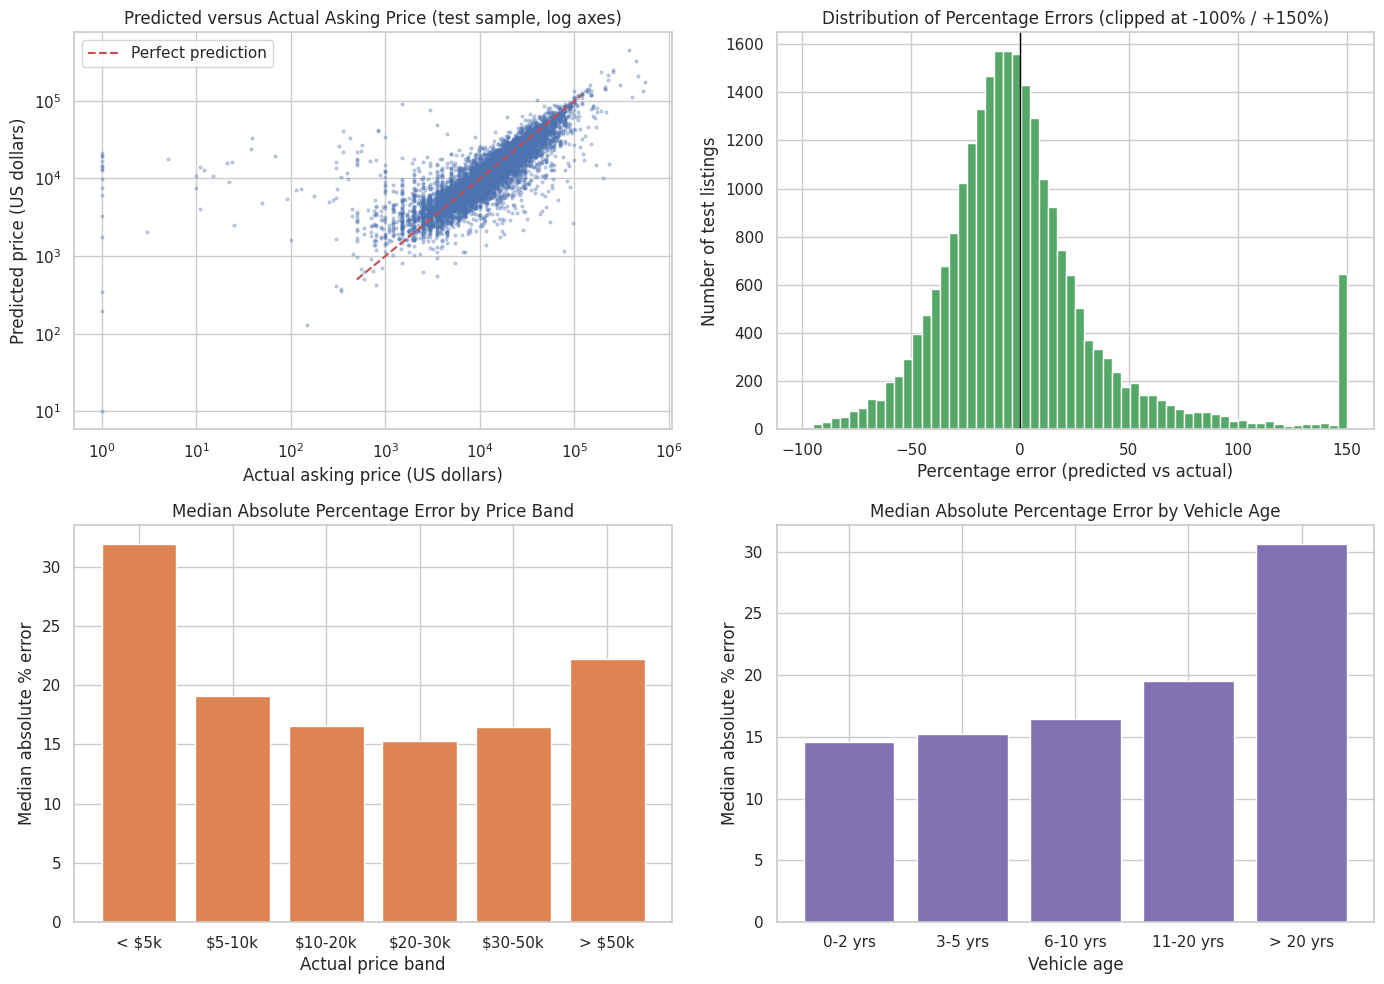

Error by price band:


,median,listings
price_band,,
< $5k,31.9,4051
$5-10k,19.1,5599
$10-20k,16.6,7246
$20-30k,15.3,3461
$30-50k,16.5,2533
> $50k,22.2,1110


The model is least accurate for the '< $5k' band (median error 31.9%).
Median signed error: -4.6% (tends to under-estimate slightly).

Ten largest errors (for manual review - often placeholder prices or unusual vehicles):


,manufacturer,model,year,odometer,actual,predicted,pct_error
190651,ford,bronco,1968.0,52753.0,1.0,21494.0,2149259.0
89278,jeep,wrangler rubicon,2015.0,30000.0,1.0,20740.0,2073929.0
95254,chrysler,town and country,2018.0,70000.0,1.0,19391.0,1939026.0
93790,ford,f-150,2013.0,150000.0,1.0,19257.0,1925593.0
66837,unknown,various,2020.0,20000.0,1.0,17012.0,1701111.0
212971,nissan,maxima,2021.0,56322.0,1.0,16603.0,1660202.0
31083,ford,f250,2015.0,122817.0,1.0,14536.0,1453545.0
98195,chevrolet,silverado 1500,2012.0,123456.0,1.0,14455.0,1445402.0
90644,ford,explorer,2025.0,80000.0,1.0,13425.0,1342376.0
43842,buick,riviera,1977.0,141000.0,1.0,12820.0,1281856.0


In [ ]:
errors = X_test.copy()
errors["actual"], errors["predicted"] = y_test.values, np.clip(pred_test, 1, None)
errors["pct_error"] = (errors["predicted"] - errors["actual"]) / errors["actual"] * 100
errors["ape"] = errors["pct_error"].abs()

price_bins = [0, 5_000, 10_000, 20_000, 30_000, 50_000, np.inf]
price_labels = ["< $5k", "$5-10k", "$10-20k", "$20-30k", "$30-50k", "> $50k"]
errors["price_band"] = pd.cut(errors["actual"], bins=price_bins, labels=price_labels)
errors["age_band"] = pd.cut(vf.REFERENCE_YEAR - pd.to_numeric(errors["year"], errors="coerce"), bins=[-1, 2, 5, 10, 20, 200],
                            labels=["0-2 yrs", "3-5 yrs", "6-10 yrs", "11-20 yrs", "> 20 yrs"])

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
sample_e = errors.sample(n=min(10_000, len(errors)), random_state=42)
axes[0, 0].scatter(sample_e["actual"], sample_e["predicted"], s=4, alpha=0.3, color="#4C72B0")
lim = [max(sample_e["actual"].min(), 500), sample_e["actual"].quantile(0.995)]
axes[0, 0].plot(lim, lim, color="#C44E52", linestyle="--", label="Perfect prediction")
axes[0, 0].set_xscale("log"); axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Predicted versus Actual Asking Price (test sample, log axes)")
axes[0, 0].set_xlabel("Actual asking price (US dollars)")
axes[0, 0].set_ylabel("Predicted price (US dollars)")
axes[0, 0].legend()

axes[0, 1].hist(errors["pct_error"].clip(-100, 150), bins=60, color="#55A868")
axes[0, 1].axvline(0, color="black", linewidth=1)
axes[0, 1].set_title("Distribution of Percentage Errors (clipped at -100% / +150%)")
axes[0, 1].set_xlabel("Percentage error (predicted vs actual)")
axes[0, 1].set_ylabel("Number of test listings")

band_stats = errors.groupby("price_band", observed=True)["ape"].agg(median="median", listings="count")
axes[1, 0].bar(band_stats.index.astype(str), band_stats["median"], color="#DD8452")
axes[1, 0].set_title("Median Absolute Percentage Error by Price Band")
axes[1, 0].set_xlabel("Actual price band")
axes[1, 0].set_ylabel("Median absolute % error")

age_stats = errors.groupby("age_band", observed=True)["ape"].agg(median="median", listings="count")
axes[1, 1].bar(age_stats.index.astype(str), age_stats["median"], color="#8172B3")
axes[1, 1].set_title("Median Absolute Percentage Error by Vehicle Age")
axes[1, 1].set_xlabel("Vehicle age")
axes[1, 1].set_ylabel("Median absolute % error")
plt.tight_layout()
save_fig("11_error_analysis")
plt.show()

print("Error by price band:"); display(band_stats.round(1))
worst_band = band_stats["median"].idxmax()
print(f"The model is least accurate for the '{worst_band}' band (median error {band_stats['median'].max():.1f}%).")
bias = errors["pct_error"].median()
print(f"Median signed error: {bias:+.1f}% ({'tends to over-estimate' if bias > 0 else 'tends to under-estimate'} slightly).")

print("\nTen largest errors (for manual review - often placeholder prices or unusual vehicles):")
display(errors.sort_values("ape", ascending=False).head(10)[["manufacturer", "model", "year", "odometer", "actual", "predicted", "pct_error"]].round(0))

In [ ]:
# Honest price range: empirical ratios actual/predicted from OUT-OF-FOLD predictions on the tuning sample (no test data used)
oof_pred = np.clip(cross_val_predict(clone(final_pipe), X_tune, y_tune, cv=cv_splitter), 1, None)
ratios = y_tune.values / oof_pred
RATIO_LOW, RATIO_HIGH = (float(q) for q in np.quantile(ratios, [0.10, 0.90]))

inside = ((errors["actual"] >= errors["predicted"] * RATIO_LOW) & (errors["actual"] <= errors["predicted"] * RATIO_HIGH)).mean() * 100
print(f"Price range rule: estimate x {RATIO_LOW:.2f}  to  estimate x {RATIO_HIGH:.2f}  (10th to 90th percentile of historical errors).")
print(f"Check on the test set: {inside:.1f}% of actual asking prices fall inside this range (nominal target: 80%).")

Price range rule: estimate x 0.66  to  estimate x 1.71  (10th to 90th percentile of historical errors).
Check on the test set: 82.9% of actual asking prices fall inside this range (nominal target: 80%).


### Interpretation – Section 28 (business recommendations)
- **Use the estimate as a reference, not a verdict.** The accuracy differs by price band and age; the table and charts show where the model is weakest.
- **Show a range.** The 10th–90th percentile range tells the user how uncertain the estimate is. The test-set check shows whether the range is well calibrated.
- **Flag, don't auto-correct.** Listings whose asking price lies far outside the range are worth a manual look (possible bargain, typo, or unusual vehicle).
- **Monitor and retrain.** The data is a snapshot; used-car prices drift, so the model should be re-evaluated on fresh listings regularly.

## 29. What Drives the Predictions? (Feature Importance)

**What will happen?** *Permutation importance* shuffles one input column at a time on test data and measures how much the error increases. A bigger increase means the model relies more on that input.
**Why?** It explains the model in business terms and is shown in the app.

,Input,Increase in error when shuffled,std
0,year,0.2532,0.0120
1,odometer,0.1716,0.0089
2,manufacturer,0.0635,0.0011
5,cylinders,0.0598,0.0065
6,fuel,0.0447,0.0010
11,type,0.0441,0.0023
4,condition,0.0403,0.0022
14,state,0.0386,0.0031
13,seller_type,0.0363,0.0038
9,drive,0.0279,0.0001


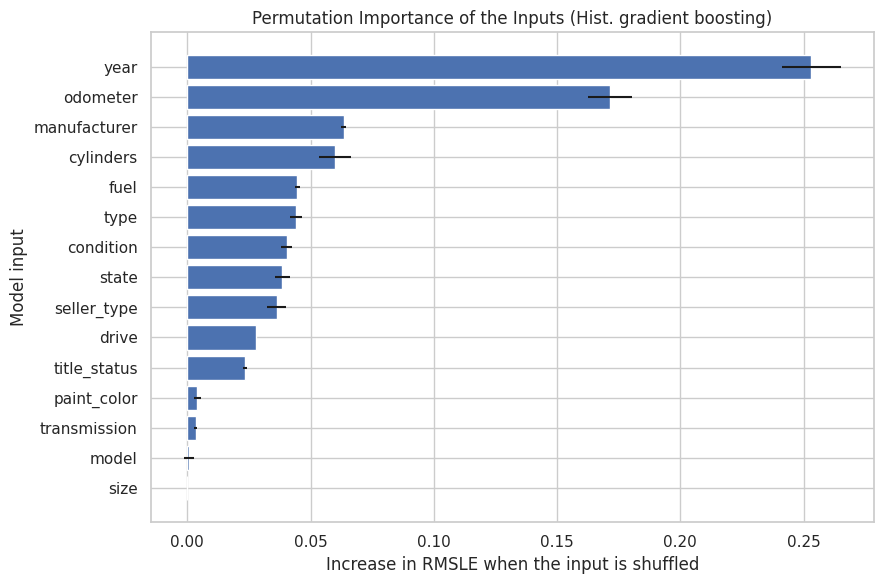

The model relies most on: year, odometer, manufacturer.
Business meaning: these are the attributes a seller should describe most carefully, and the ones that move an estimate the most.


In [ ]:
perm_sample = X_test.sample(n=min(4_000, len(X_test)), random_state=42)
perm = permutation_importance(final_pipe, perm_sample, y_test.loc[perm_sample.index], scoring=rmsle_scorer,
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.DataFrame({"Input": perm_sample.columns, "Increase in error when shuffled": perm.importances_mean,
                           "std": perm.importances_std}).sort_values("Increase in error when shuffled", ascending=False)
display(importance.round(4))

fig, ax = plt.subplots(figsize=(9, 6))
plot_imp = importance.sort_values("Increase in error when shuffled")
ax.barh(plot_imp["Input"], plot_imp["Increase in error when shuffled"], xerr=plot_imp["std"], color="#4C72B0")
ax.set_title(f"Permutation Importance of the Inputs ({FINAL_MODEL_NAME})")
ax.set_xlabel("Increase in RMSLE when the input is shuffled")
ax.set_ylabel("Model input")
plt.tight_layout()
save_fig("12_permutation_importance")
DOCS_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(DOCS_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")     # reused by the Streamlit app
plt.show()
importance.to_csv(OUTPUT_DIR / "permutation_importance.csv", index=False)

top_inputs = importance["Input"].head(3).tolist()
print(f"The model relies most on: {', '.join(top_inputs)}.")
print("Business meaning: these are the attributes a seller should describe most carefully, and the ones that move an estimate the most.")

### Interpretation – Stage 6
The final model, its tuning history, its evaluation against the Stage 1 targets, its error pattern and its drivers are now documented. Everything needed for the report (tables in `outputs/`, figures in `outputs/figures/`) has been saved. Section 30 below saves the final model for the web application (notebook 04).

## 30. Save the Final Model and its Metadata (input of notebook 04)

**What will happen?** The trained pipeline (feature engineering + preprocessing + model) is saved with `joblib`, together with a small JSON file that the app needs: lists of valid categories, the model list per manufacturer, the price-range ratios, the evaluation metrics and the library versions.

**Why metadata?** The app builds its drop-down menus from the training data, so users can only choose values the model has seen. Saving library versions prevents version-mismatch errors when the app is deployed.

In [ ]:
import json
import joblib
import pandas as pd
import numpy as np
from datetime import date

MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "price_model.joblib"
joblib.dump(final_pipe, model_path, compress=3)
model_size_mb = model_path.stat().st_size / 1024**2
print(f"Saved model: {model_path.name} ({model_size_mb:,.1f} MB)")
if model_size_mb > 90:
    print("WARNING: the model file is close to / above GitHub's 100 MB limit. Use gradient boosting or fewer/shallower forest trees "
          "(lower RF_TREES, add max_depth) and re-run Stages 5-6 before pushing to GitHub.")

# ---- Metadata for the app ----
train_clean = vf.add_features(X_train)                      # standardised categories exactly as the model sees them
categories = {}
for col in vf.CATEGORICAL_RAW:
    if col == "model":
        continue
    counts = train_clean[col].value_counts()
    keep = sorted(counts[counts >= MIN_CAT_FREQ].index.tolist())
    if "unknown" in counts.index and "unknown" not in keep:
        keep.append("unknown")
    categories[col] = ["unknown"] + [v for v in keep if v != "unknown"] if "unknown" in keep else keep

models_by_manufacturer = {}
for maker in categories["manufacturer"]:
    if maker == "unknown":
        continue
    counts = train_clean.loc[train_clean["manufacturer"] == maker, "model"].value_counts()
    models_by_manufacturer[maker] = sorted(counts[(counts >= 5) & (counts.index != "unknown")].head(80).index.tolist())

metadata = {
    "model_name": FINAL_MODEL_NAME,
    "created": str(date.today()),
    "reference_year": int(vf.REFERENCE_YEAR),
    "training_rows": int(len(X_train)),
    "test_metrics": {k: round(float(v), 4) for k, v in final_metrics.items()},
    "ratio_low": RATIO_LOW, "ratio_high": RATIO_HIGH,
    "categories": categories,
    "models_by_manufacturer": models_by_manufacturer,
    "library_versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__,
                         "joblib": joblib.__version__, "python": sys.version.split()[0]},
}
metadata_path = MODEL_DIR / "model_metadata.json"
metadata_path.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print(f"Saved metadata: {metadata_path.name}")
print(f"Manufacturers offered in the app: {len(models_by_manufacturer)} | categories per field: { {k: len(v) for k, v in categories.items()} }")

Saved model: price_model.joblib (2.9 MB)
Saved metadata: model_metadata.json
Manufacturers offered in the app: 36 | categories per field: {'manufacturer': 37, 'condition': 7, 'cylinders': 9, 'fuel': 6, 'title_status': 5, 'transmission': 4, 'drive': 4, 'size': 1, 'type': 14, 'paint_color': 13, 'seller_type': 2, 'state': 51}


In [ ]:
# Verify that the saved file gives exactly the same predictions as the model in memory
reloaded = joblib.load(model_path)
check_rows = X_test.head(50)
assert np.allclose(reloaded.predict(check_rows), final_pipe.predict(check_rows)), "Reloaded model differs from the trained model!"
print("Reloaded model reproduces the in-memory predictions exactly.")

Reloaded model reproduces the in-memory predictions exactly.


---
## Next step
Notebook 03 is finished. The final model, its metadata, all evaluation tables and figures are saved in your Drive folder.

**Open notebook `04_stage_7_deployment.ipynb` next.**